# Multi-View Breast Cancer Detection Prototype (PyTorch)
A simple prototype using a dual-input ResNet18 architecture.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


KeyboardInterrupt: 

In [ ]:
print('torch:', torch.__version__)
print('torch cuda build:', torch.version.cuda)
print('cuda available:', torch.cuda.is_available())
print('device:', device)
if torch.cuda.is_available():
    print('cuda device name:', torch.cuda.get_device_name(0))


torch: 2.6.0+cu124
torch cuda build: 12.4
cuda available: True
device: cuda
cuda device name: NVIDIA GeForce RTX 3070


In [ ]:
torch.manual_seed(42)
np.random.seed(42)

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])


In [ ]:
# Single-View Baseline CNN — backbone: 'resnet50', 'densenet121', or 'efficientnet'
class SingleViewCNN(nn.Module):
    def __init__(self, backbone='resnet50'):
        super().__init__()
        if backbone == 'resnet50':
            net = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            self.encoder = nn.Sequential(*list(net.children())[:-1])
            feat_size = 2048
        elif backbone == 'densenet121':
            net = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
            self.encoder = nn.Sequential(net.features, nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1)))
            feat_size = 1024
        elif backbone == 'efficientnet':
            net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            self.encoder = nn.Sequential(net.features, net.avgpool)
            feat_size = 1280
        else:
            raise ValueError(f"Unknown backbone: {backbone!r}")
        self.classifier = nn.Sequential(nn.Linear(feat_size, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 2))

    def forward(self, x):
        x = self.encoder(x).flatten(1)
        return self.classifier(x)

single_model = SingleViewCNN(backbone='densenet121').to(device)
# Lower lr for pretrained backbone, higher lr for new classifier head
optimizer_single = torch.optim.Adam([
    {'params': single_model.encoder.parameters(), 'lr': 1e-5},
    {'params': single_model.classifier.parameters(), 'lr': 1e-4},
])
criterion = nn.CrossEntropyLoss()  # overridden with class weights after data loading


In [ ]:
class MultiViewDataset(Dataset):
    def __init__(self, csv_file=None, transform=None, df=None):
        self.df = df if df is not None else pd.read_csv(csv_file)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        cc_path = row['cc_path']
        mlo_path = row['mlo_path']
        cc = Image.open(cc_path).convert('RGB')
        mlo = Image.open(mlo_path).convert('RGB')
        y = int(row['label'])
        if self.transform:
            cc = self.transform(cc)
            mlo = self.transform(mlo)
        return cc, mlo, y


In [ ]:
# CBIS-DDSM dataset
DATA_ROOT = Path.cwd()
if not (DATA_ROOT / 'archive').exists() and (DATA_ROOT / 'FYP' / 'archive').exists():
    DATA_ROOT = DATA_ROOT / 'FYP'
CSV_ROOT = DATA_ROOT / 'archive' / 'csv'

def build_shared_dataframe(case_csv):
    if not case_csv.exists():
        print(f"Warning: {case_csv} not found")
        return pd.DataFrame(columns=['cc_path', 'mlo_path', 'label'])
    cases = pd.read_csv(case_csv).copy()
    cases['case_id_full'] = cases['image file path'].astype(str).str.split('/', n=1).str[0]
    cases['case_key'] = cases['case_id_full'].str.rsplit('_', n=1).str[0]
    cases['view'] = cases['image view'].astype(str).str.strip().str.upper()
    cases['label'] = cases['pathology'].astype(str).str.upper().eq('MALIGNANT').astype(int)
    cases = cases[cases['view'].isin(['CC', 'MLO'])].copy()
    dicom_map = pd.read_csv(CSV_ROOT / 'dicom_info.csv')[['PatientID', 'SeriesDescription', 'image_path']]
    dicom_map = dicom_map[dicom_map['SeriesDescription'].eq('full mammogram images')].copy()
    merged = cases.merge(dicom_map, left_on='case_id_full', right_on='PatientID', how='left')
    merged = merged.dropna(subset=['image_path'])
    merged['image_path'] = merged['image_path'].apply(lambda p: str(DATA_ROOT / 'archive' / p.replace('CBIS-DDSM/', '')))
    pivoted = merged.pivot_table(
        index=['case_key', 'label'],
        columns='view',
        values='image_path',
        aggfunc='first'
    ).reset_index()
    pivoted.columns.name = None
    if 'CC' not in pivoted.columns or 'MLO' not in pivoted.columns:
        raise ValueError(f"No CC/MLO pairs found for {case_csv.name}; verify image view labels and dicom_info.csv.")
    result = pivoted[['CC', 'MLO', 'label']].dropna(subset=['CC', 'MLO']).copy()
    result = result.rename(columns={'CC': 'cc_path', 'MLO': 'mlo_path'})
    if result.empty:
        raise ValueError(f"No paired CC/MLO samples found for {case_csv.name}; check your mapping logic.")
    sample_path = Path(result.iloc[0]['cc_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved CC path does not exist: {sample_path}")
    sample_path = Path(result.iloc[0]['mlo_path'])
    if not sample_path.exists():
        raise FileNotFoundError(f"Resolved MLO path does not exist: {sample_path}")
    print(f"Loaded {len(result)} CC/MLO pairs from {case_csv.name}")
    return result


train_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_train_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_train_set.csv'),
], ignore_index=True)

test_pairs = pd.concat([
    build_shared_dataframe(CSV_ROOT / 'calc_case_description_test_set.csv'),
    build_shared_dataframe(CSV_ROOT / 'mass_case_description_test_set.csv'),
], ignore_index=True)

train_dataset = MultiViewDataset(df=train_pairs, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_dataset = MultiViewDataset(df=test_pairs, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Class-weighted loss to handle benign/malignant imbalance
counts = train_pairs['label'].value_counts().sort_index()
class_weights = torch.tensor([1.0 / counts[0], 1.0 / counts[1]], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print(f"Class weights — Benign: {class_weights[0]:.4f}, Malignant: {class_weights[1]:.4f}")


Loaded 568 CC/MLO pairs from calc_case_description_train_set.csv
Loaded 512 CC/MLO pairs from mass_case_description_train_set.csv
Loaded 5 CC/MLO pairs from calc_case_description_test_set.csv
Loaded 151 CC/MLO pairs from mass_case_description_test_set.csv
Class weights — Benign: 0.0017, Malignant: 0.0021


In [ ]:
def train_single(loader):
    single_model.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, y = cc.to(device), y.to(device)
        optimizer_single.zero_grad()
        out = single_model(cc)
        loss = criterion(out, y)
        loss.backward()
        optimizer_single.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate_single(loader):
    single_model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for cc, mlo, y in loader:
            pred = torch.argmax(single_model(cc.to(device)), 1).cpu().numpy()
            preds.extend(pred)
            labels.extend(y.numpy())
    acc  = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, average='macro', zero_division=0)
    rec  = recall_score(labels, preds, average='macro', zero_division=0)
    f1   = f1_score(labels, preds, average='macro', zero_division=0)
    return acc, prec, rec, f1


In [ ]:
# Multi-View DenseNet121 Model
class MultiViewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        self.encoder = nn.Sequential(backbone.features, nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Linear(2048,256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256,2)
        )
    def forward(self, cc, mlo):
        cc = self.encoder(cc).flatten(1)
        mlo = self.encoder(mlo).flatten(1)
        x = torch.cat([cc, mlo], dim=1)
        return self.classifier(x)

model = MultiViewCNN().to(device)


In [ ]:
optimizer_multi = torch.optim.Adam(model.parameters(), lr=1e-4)


def train_epoch(loader):
    model.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        optimizer_multi.zero_grad()
        out = model(cc, mlo)
        loss = criterion(out, y)
        loss.backward()
        optimizer_multi.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(loader):
    model.eval()
    preds = []
    labels = []
    with torch.no_grad():
        for cc, mlo, y in loader:
            cc, mlo = cc.to(device), mlo.to(device)
            out = model(cc, mlo)
            pred = torch.argmax(out, 1).cpu().numpy()
            preds.extend(pred)
            labels.extend(y.numpy())
    return accuracy_score(labels, preds)


In [ ]:
## Knowledge Distillation & Cross-Architecture Transfer
## - **Multi-View → ResNet50**: multi-view model acts as teacher to improve single-view ResNet50
## - **ResNet50 → DenseNet121 / EfficientNet**: cross-architecture distillation using the trained ResNet50 as teacher


In [ ]:
EPOCHS = 3
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_single, T_max=EPOCHS)

single_losses = []
for e in range(EPOCHS):
    single_loss = train_single(train_loader)
    single_losses.append(single_loss)
    scheduler.step()
    print(f'Epoch {e+1}: Single Loss={single_loss:.4f}')

acc, prec, rec, f1 = evaluate_single(test_loader)
print(f"\nSingle-View Results:")
print(f"  Accuracy:  {acc:.4f}")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1 Score:  {f1:.4f}")


Epoch 1: Single Loss=0.6947
Epoch 2: Single Loss=0.6650
Epoch 3: Single Loss=0.6565

Single-View Results:
  Accuracy:  0.5705
  Precision: 0.5527
  Recall:    0.5530
  F1 Score:  0.5529


Epoch 1: Multi Loss=0.6673
Epoch 2: Multi Loss=0.6274
Epoch 3: Multi Loss=0.5764

Multi-View Results:
  Accuracy:  0.5962
  Precision: 0.6288
  Recall:    0.6265
  F1 Score:  0.5960


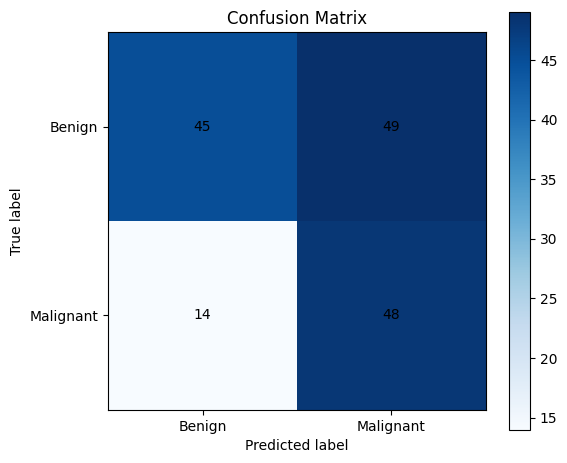

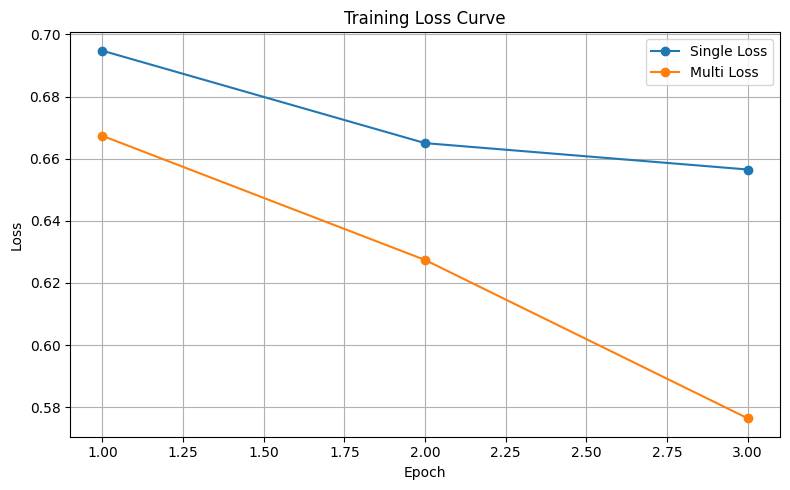

In [ ]:
multi_losses = []
for e in range(EPOCHS):
    multi_loss = train_epoch(train_loader)
    multi_losses.append(multi_loss)
    print(f'Epoch {e+1}: Multi Loss={multi_loss:.4f}')

y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for cc, mlo, y in test_loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        out = model(cc, mlo)
        pred = torch.argmax(out, 1)
        y_true.extend(y.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())

print(f"\nMulti-View Results:")
print(f"  Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"  Precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"  Recall:    {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"  F1 Score:  {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Benign', 'Malignant'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Benign', 'Malignant'])
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, EPOCHS + 1), single_losses, marker='o', label='Single Loss')
ax.plot(range(1, EPOCHS + 1), multi_losses, marker='o', label='Multi Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Loss Curve')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import torch.nn.functional as F

def distillation_loss(student_logits, teacher_logits, labels, T=4.0, alpha=0.5):
    soft_student = F.log_softmax(student_logits / T, dim=1)
    soft_teacher = F.softmax(teacher_logits / T, dim=1)
    # scale by T^2 to keep gradient magnitudes consistent with CE loss
    kd_loss = F.kl_div(soft_student, soft_teacher, reduction='batchmean') * (T ** 2)
    return alpha * criterion(student_logits, labels) + (1 - alpha) * kd_loss

def train_distilled(student, opt, loader, get_teacher_logits, T=4.0, alpha=0.5):
    student.train()
    total_loss = 0.0
    for cc, mlo, y in loader:
        cc, mlo, y = cc.to(device), mlo.to(device), y.to(device)
        opt.zero_grad()
        with torch.no_grad():
            teacher_logits = get_teacher_logits(cc, mlo)
        loss = distillation_loss(student(cc), teacher_logits, y, T, alpha)
        loss.backward()
        opt.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def eval_sv(mdl, loader):
    mdl.eval()
    preds, labels = [], []
    with torch.no_grad():
        for cc, mlo, y in loader:
            pred = torch.argmax(mdl(cc.to(device)), 1).cpu().numpy()
            preds.extend(pred); labels.extend(y.numpy())
    return (accuracy_score(labels, preds),
            precision_score(labels, preds, average='macro', zero_division=0),
            recall_score(labels, preds, average='macro', zero_division=0),
            f1_score(labels, preds, average='macro', zero_division=0))

def eval_mv(mdl, loader):
    mdl.eval()
    preds, labels = [], []
    with torch.no_grad():
        for cc, mlo, y in loader:
            pred = torch.argmax(mdl(cc.to(device), mlo.to(device)), 1).cpu().numpy()
            preds.extend(pred); labels.extend(y.numpy())
    return (accuracy_score(labels, preds),
            precision_score(labels, preds, average='macro', zero_division=0),
            recall_score(labels, preds, average='macro', zero_division=0),
            f1_score(labels, preds, average='macro', zero_division=0))


In [ ]:
model.eval()
distilled_resnet = SingleViewCNN(backbone='resnet50').to(device)
opt_dr = torch.optim.Adam([
    {'params': distilled_resnet.encoder.parameters(), 'lr': 1e-5},
    {'params': distilled_resnet.classifier.parameters(), 'lr': 1e-4},
])
sched_dr = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dr, T_max=EPOCHS)

print("=== Distillation: Multi-View Teacher → ResNet50 Student ===")
for e in range(EPOCHS):
    loss = train_distilled(distilled_resnet, opt_dr, train_loader,
                           get_teacher_logits=lambda cc, mlo: model(cc, mlo))
    sched_dr.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_dr, prec_dr, rec_dr, f1_dr = eval_sv(distilled_resnet, test_loader)
print(f"\nDistilled ResNet50 (Multi-View Teacher):")
print(f"  Acc={acc_dr:.4f} | Prec={prec_dr:.4f} | Rec={rec_dr:.4f} | F1={f1_dr:.4f}")


=== Distillation: Multi-View Teacher → ResNet50 Student ===
Epoch 1: Loss=0.4059
Epoch 2: Loss=0.3925
Epoch 3: Loss=0.3800

Distilled ResNet50 (Multi-View Teacher):
  Acc=0.5577 | Prec=0.4935 | Rec=0.4957 | F1=0.4715


In [ ]:
single_model.eval()

# ResNet50 → DenseNet121
densenet_student = SingleViewCNN(backbone='densenet121').to(device)
opt_dn = torch.optim.Adam([
    {'params': densenet_student.encoder.parameters(), 'lr': 1e-5},
    {'params': densenet_student.classifier.parameters(), 'lr': 1e-4},
])
sched_dn = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dn, T_max=EPOCHS)

print("=== Cross-Architecture: ResNet50 Teacher → DenseNet121 Student ===")
for e in range(EPOCHS):
    loss = train_distilled(densenet_student, opt_dn, train_loader,
                           get_teacher_logits=lambda cc, mlo: single_model(cc))
    sched_dn.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_dn, prec_dn, rec_dn, f1_dn = eval_sv(densenet_student, test_loader)
print(f"\nDistilled DenseNet121: Acc={acc_dn:.4f} | Prec={prec_dn:.4f} | Rec={rec_dn:.4f} | F1={f1_dn:.4f}")

# ResNet50 → EfficientNet
effnet_student = SingleViewCNN(backbone='efficientnet').to(device)
opt_en = torch.optim.Adam([
    {'params': effnet_student.encoder.parameters(), 'lr': 1e-5},
    {'params': effnet_student.classifier.parameters(), 'lr': 1e-4},
])
sched_en = torch.optim.lr_scheduler.CosineAnnealingLR(opt_en, T_max=EPOCHS)

print("\n=== Cross-Architecture: ResNet50 Teacher → EfficientNet Student ===")
for e in range(EPOCHS):
    loss = train_distilled(effnet_student, opt_en, train_loader,
                           get_teacher_logits=lambda cc, mlo: single_model(cc))
    sched_en.step()
    print(f'Epoch {e+1}: Loss={loss:.4f}')

acc_en, prec_en, rec_en, f1_en = eval_sv(effnet_student, test_loader)
print(f"\nDistilled EfficientNet: Acc={acc_en:.4f} | Prec={prec_en:.4f} | Rec={rec_en:.4f} | F1={f1_en:.4f}")


=== Cross-Architecture: ResNet50 Teacher → DenseNet121 Student ===
Epoch 1: Loss=0.3577
Epoch 2: Loss=0.3358
Epoch 3: Loss=0.3307

Distilled DenseNet121: Acc=0.5513 | Prec=0.5340 | Rec=0.5343 | F1=0.5341


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Enzo/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100.0%



=== Cross-Architecture: ResNet50 Teacher → EfficientNet Student ===
Epoch 1: Loss=0.3551
Epoch 2: Loss=0.3428
Epoch 3: Loss=0.3402

Distilled EfficientNet: Acc=0.5897 | Prec=0.5407 | Rec=0.5251 | F1=0.5003


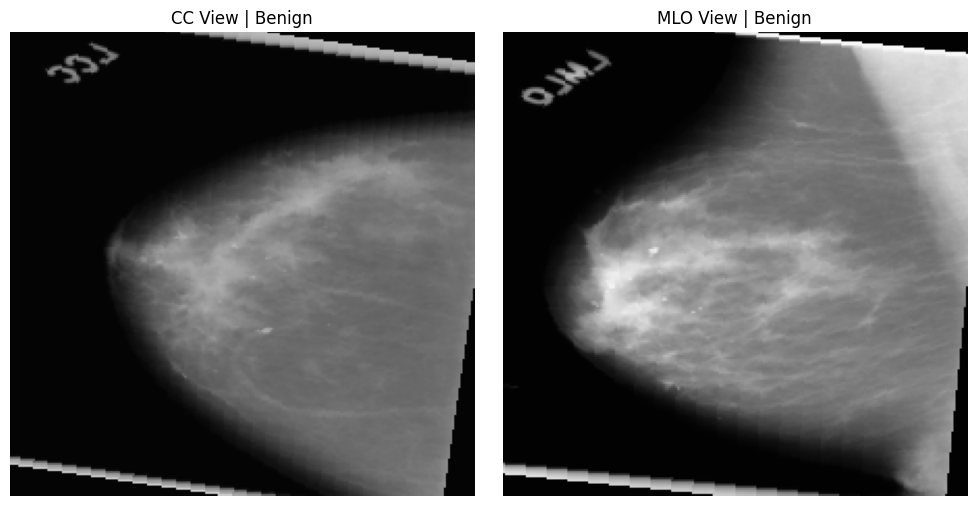

In [ ]:
sample_idx = np.random.randint(len(train_dataset))
sample_cc, sample_mlo, sample_y = train_dataset[sample_idx]
sample_cc = sample_cc.mul(0.5).add(0.5).clamp(0, 1)
sample_mlo = sample_mlo.mul(0.5).add(0.5).clamp(0, 1)
label_text = 'Malignant' if sample_y == 1 else 'Benign'

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sample_cc.permute(1, 2, 0))
ax[0].set_title(f'CC View | {label_text}')
ax[0].axis('off')

ax[1].imshow(sample_mlo.permute(1, 2, 0))
ax[1].set_title(f'MLO View | {label_text}')
ax[1].axis('off')

plt.tight_layout()

In [ ]:
# Re-evaluates all models and prints a single results table
summary_data = {
    'Single-View DenseNet121':       eval_sv(single_model, test_loader),
    'Multi-View DenseNet121':        eval_mv(model, test_loader),
    'KD: Multi-View → ResNet50':     eval_sv(distilled_resnet, test_loader),
    'KD: ResNet50 → DenseNet121':    eval_sv(densenet_student, test_loader),
    'KD: ResNet50 → EfficientNet':   eval_sv(effnet_student, test_loader),
}

summary_df = pd.DataFrame(
    [(name,) + metrics for name, metrics in summary_data.items()],
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'],
).set_index('Model').round(4)

print(summary_df.to_string())


                             Accuracy  Precision  Recall      F1
Model                                                           
Single-View ResNet50           0.5705     0.5527  0.5530  0.5529
Multi-View CNN                 0.5962     0.6288  0.6265  0.5960
KD: Multi-View → ResNet50      0.5577     0.4935  0.4957  0.4715
KD: ResNet50 → DenseNet121     0.5513     0.5340  0.5343  0.5341
KD: ResNet50 → EfficientNet    0.5897     0.5407  0.5251  0.5003
